# 10.9. Evaluación temporal y diagnósticos

El análisis utiliza los mismos 1.461 días y las cinco realizaciones de cada configuración. La unidad temporal es el origen diario con sus 24 errores. Se distingue variación entre semillas, entre fechas y entre segmentos; ninguna se interpreta como una nueva muestra independiente de mercados.

In [1]:
from pathlib import Path
import json,hashlib,itertools
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'results/jbook/modelos_actualizados.json').exists())
procedencia=json.loads((ROOT/'results/jbook/modelos_actualizados.json').read_text(encoding='utf-8'))
SHA=procedencia['commit'];SNAP=ROOT/'results/repositorio'/SHA
C=SNAP/'results/consolidado';OUT=ROOT/'results/jbook/modelos_actuales';OUT.mkdir(parents=True,exist_ok=True)
registro=json.loads((C/'modelos.json').read_text(encoding='utf-8'))
modelos=['mlp','arx_lineal','cnn1d','lstm'];neuronales=['mlp','cnn1d','lstm']
etiquetas={'mlp':'MLP','arx_lineal':'ARX','cnn1d':'CNN1D','lstm':'LSTM','ingenuo_24h':'Ingenuo diario','ingenuo_168h':'Ingenuo semanal'}
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
importacion=json.loads((SNAP/'IMPORTACION.json').read_text(encoding='utf-8'))
huellas={x['archivo']:x for x in importacion['archivos']}
indice=pd.read_csv(C/'indice_artefactos_v3_v4.csv')
assert len(indice)==2304 and not indice.archivo.duplicated().any()
for fila in indice.itertuples():
    p=SNAP/fila.archivo
    assert p.stat().st_size==fila.bytes
    assert hashlib.sha256(p.read_bytes()).hexdigest()==fila.sha256==huellas[fila.archivo]['sha256']
runs=[];pilotos=[];confirmaciones=[];filtros=[];pred={};carpetas={};escaladores={};historias={};y=None;origen=None
for nombre in modelos:
    r=registro[nombre];carpeta=SNAP/'results'/r['ejecucion']
    seleccion=r['configuracion']['id']
    pp=pd.read_csv(carpeta/'piloto.csv');pp=pp.loc[(pp.modelo==nombre)&(pp.configuracion==seleccion)]
    assert len(pp)==20 and not pp.duplicated(['semilla','fold']).any()
    pilotos.append(pp)
    pila=[]
    for a in sorted(r['artefactos'],key=lambda a:a['semilla']):
        met=json.loads((SNAP/a['metricas']).read_text(encoding='utf-8'))
        esc=json.loads((SNAP/a['escaladores']).read_text(encoding='utf-8'))
        historia=pd.DataFrame(json.loads((SNAP/a['historial']).read_text(encoding='utf-8')))
        assert met['semilla']==a['semilla'] and met['params']==r['configuracion']['params']
        assert met['configuracion']==seleccion and len(historia)==met['epocas']
        assert historia.epoca.tolist()==list(range(1,len(historia)+1))
        assert met['mejor_epoca']==int(historia.val_loss.idxmin()+1)
        assert pd.Timestamp(esc['fin_ajuste'])<pd.Timestamp('2022-01-01',tz='America/Bogota')
        with np.load(SNAP/a['predicciones'],allow_pickle=False) as z:
            if y is None:y=z['y'].astype(float);origen=z['origen'].copy()
            assert np.array_equal(y,z['y']) and np.array_equal(origen,z['origen'])
            assert z['yhat'].shape==y.shape and np.isfinite(z['yhat']).all()
            pila.append(z['yhat'].astype(float))
        runs.append(met);historias[(nombre,a['semilla'])]=historia
        carpetas[(nombre,a['semilla'])]=SNAP/a['pesos']
        escaladores[(nombre,a['semilla'])]=esc
    pred[nombre]=np.stack(pila)
piloto=pd.concat(pilotos,ignore_index=True);runs=pd.DataFrame(runs)
assert len(runs)==20 and not runs.duplicated(['modelo','semilla']).any()
assert all(set(d.semilla)==set(range(1000,1005)) for _,d in runs.groupby('modelo'))
fechas=pd.to_datetime(origen,unit='ns',utc=True).tz_convert('America/Bogota')
assert fechas.equals(pd.date_range('2022-01-01','2025-12-31',freq='D',tz='America/Bogota'))
assert y.shape==(1461,24) and np.isfinite(y).all()
escala=float(escaladores[('mlp',1000)]['escala_mase'])
loss_h={};loss_d={};residuos={};calculadas=[]
for nombre in modelos:
    errores=pred[nombre]-y[None,:,:]
    loss_h[nombre]=np.abs(errores).mean(axis=0)/escala
    loss_d[nombre]=loss_h[nombre].mean(axis=1)
    residuos[nombre]=errores[0]
    for j,semilla in enumerate(range(1000,1005)):
        e=errores[j];mae=np.abs(e).mean();rmse=np.sqrt(np.mean(e**2))
        m=dict(modelo=nombre,semilla=semilla,MASE=mae/escala,MAE=mae,RMSE=rmse,R2=1-np.mean(e**2)/np.var(y),sesgo=e.mean(),sMAPE=(200*np.abs(e)/(np.abs(pred[nombre][j])+np.abs(y))).mean())
        original=runs.loc[(runs.modelo==nombre)&(runs.semilla==semilla)].iloc[0]
        assert np.allclose([m[k] for k in ['MASE','MAE','RMSE','sMAPE']],[original[k] for k in ['MASE','MAE','RMSE','sMAPE']],rtol=2e-6)
        calculadas.append(m)
calculadas=pd.DataFrame(calculadas)
seleccion_publicada=pd.read_csv(C/'modelos_seleccionados.csv').set_index('modelo')
assert np.allclose(calculadas.groupby('modelo').MASE.mean().sort_index(),seleccion_publicada.MASE_prueba.sort_index())
referencias=json.loads((C/'referencias_test.json').read_text(encoding='utf-8'))
filas=[]
for nombre in modelos:
    d=calculadas.loc[calculadas.modelo==nombre];media=d.MASE.mean();sd=d.MASE.std(ddof=1);ancho=stats.t.ppf(.975,len(d)-1)*sd/np.sqrt(len(d))
    filas.append(dict(familia=nombre,Modelo=etiquetas[nombre],n=len(d),MASE=media,DE=sd,IC95_inf=media-ancho,IC95_sup=media+ancho,MAE_kWh=d.MAE.mean(),RMSE_kWh=d.RMSE.mean(),sMAPE_pct=d.sMAPE.mean(),R2=d.R2.mean(),sesgo_kWh=d.sesgo.mean(),parametros=int(runs.loc[runs.modelo==nombre,'n_parametros'].iloc[0]),ajuste_s=float(runs.loc[runs.modelo==nombre,'segundos'].median())))
for nombre,m in referencias.items():
    filas.append(dict(familia=nombre,Modelo=etiquetas[nombre],n=1,MASE=m['MASE'],DE=np.nan,IC95_inf=np.nan,IC95_sup=np.nan,MAE_kWh=m['MAE'],RMSE_kWh=m['RMSE'],sMAPE_pct=m['sMAPE'],R2=1-m['RMSE']**2/np.var(y),sesgo_kWh=np.nan,parametros=0,ajuste_s=np.nan))
benchmark=pd.DataFrame(filas).sort_values('MASE').reset_index(drop=True);benchmark.insert(0,'rango',np.arange(1,len(benchmark)+1))
benchmark.to_csv(OUT/'benchmark.csv',index=False);benchmark.to_csv(ROOT/'book/benchmark_modelos.csv',index=False)
calculadas.to_csv(OUT/'metricas_desde_predicciones.csv',index=False)
for fase,destino in [('filtro',filtros),('confirmacion',confirmaciones)]:
    for ruta in sorted(set(r['ejecucion'] for r in registro.values())):
        destino.append(pd.read_csv(SNAP/'results'/ruta/(fase+'.csv')))
filtro=pd.concat(filtros,ignore_index=True);confirmacion=pd.concat(confirmaciones,ignore_index=True)
assert len(filtro)==90 and len(confirmacion)==144
mejor=benchmark.loc[benchmark.familia=='mlp'].iloc[0]
reduccion_semanal=100*(1-mejor.MASE/referencias['ingenuo_168h']['MASE'])
mae_mlp=float(mejor.MAE_kWh);mase_mlp=float(mejor.MASE)

formato_p=lambda x: "<1e-300" if x==0 else f"{x:.3g}"


## Errores por horizonte y segmentos

Los errores absolutos se promedian primero entre inicializaciones y después entre días del segmento. Se conservan las 24 horas del pronóstico y se distinguen año, tipo de día y nivel realizado de demanda.

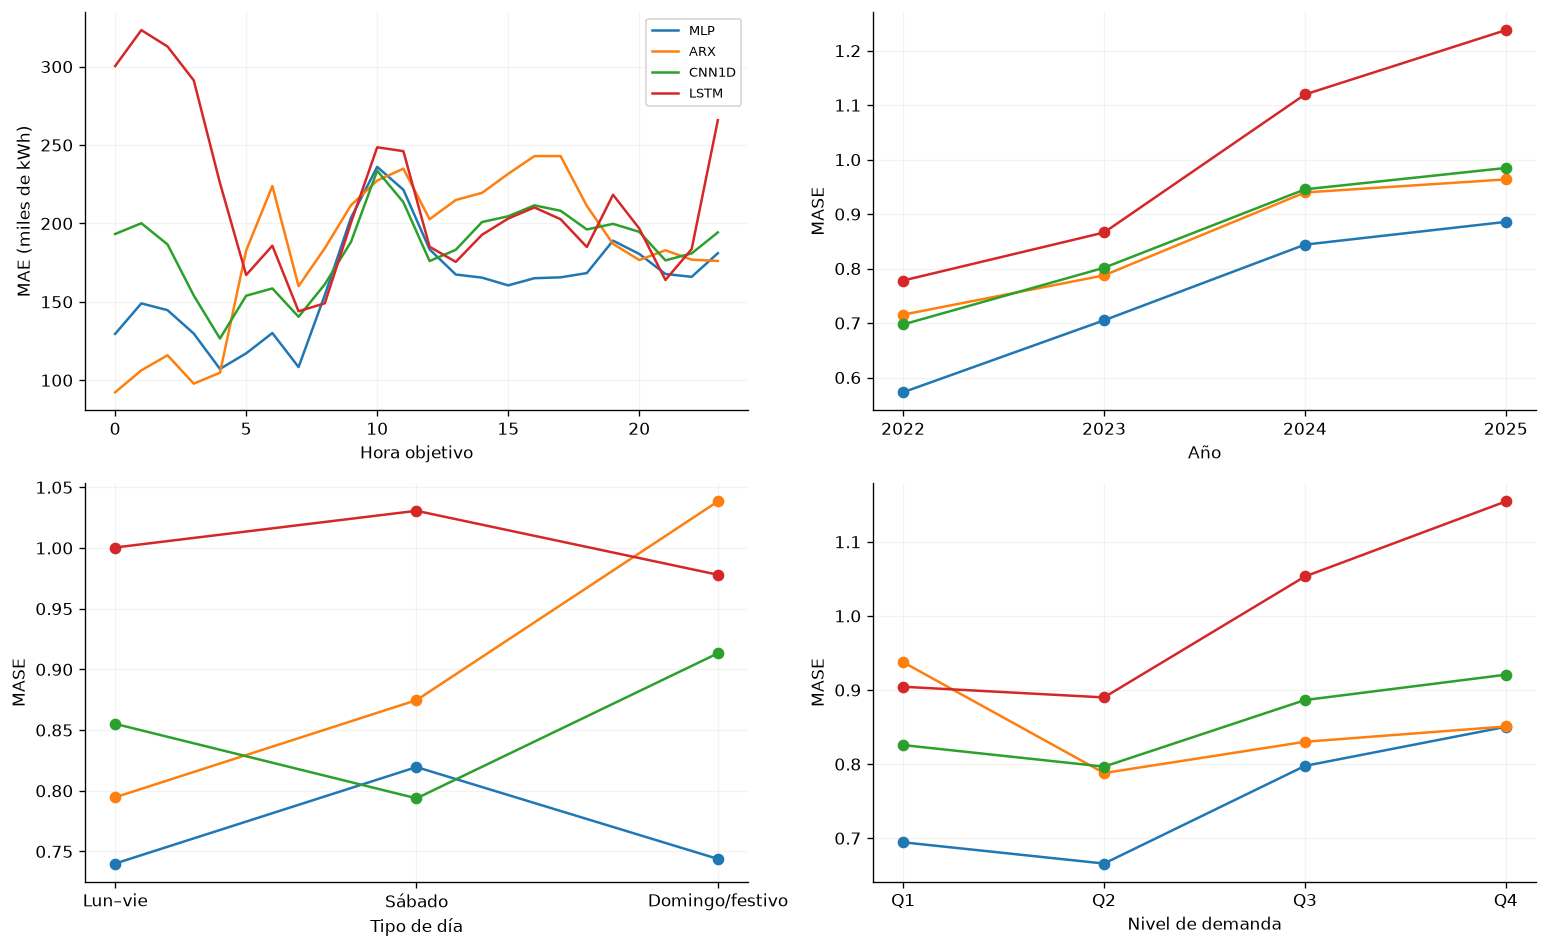

In [2]:
panel=pd.read_parquet(ROOT/'data/processed/panel_horario.parquet',columns=['cal_es_festivo'])
festivo=panel.loc[fechas,'cal_es_festivo'].to_numpy().astype(bool)
tipo=np.where((fechas.day_of_week==6)|festivo,'Domingo/festivo',np.where(fechas.day_of_week==5,'Sábado','Lun–vie'))
segmentos={'Año':fechas.year.astype(str),'Tipo de día':tipo,'Nivel de demanda':pd.qcut(y.mean(axis=1),4,labels=['Q1','Q2','Q3','Q4']).astype(str)}
filas=[];horas=[];fig,axes=plt.subplots(2,2,figsize=(13,8))
for m in modelos:
    perfil=loss_h[m].mean(axis=0);axes[0,0].plot(range(24),perfil*escala/1e3,label=etiquetas[m])
    horas.extend({'modelo':m,'hora':h,'MASE':v,'MAE_kWh':v*escala} for h,v in enumerate(perfil))
for ax,(nombre,grupos) in zip([axes[0,1],axes[1,0],axes[1,1]],segmentos.items()):
    orden=sorted(set(grupos)) if nombre!='Tipo de día' else ['Lun–vie','Sábado','Domingo/festivo']
    for m in modelos:
        valores=[loss_d[m][np.asarray(grupos)==g].mean() for g in orden];ax.plot(orden,valores,marker='o',label=etiquetas[m])
        filas.extend({'modelo':m,'segmento':nombre,'grupo':g,'n_dias':int((np.asarray(grupos)==g).sum()),'MASE':v} for g,v in zip(orden,valores))
    ax.set(xlabel=nombre,ylabel='MASE')
axes[0,0].set(xlabel='Hora objetivo',ylabel='MAE (miles de kWh)');axes[0,0].legend(fontsize=8)
fig.tight_layout();display(fig);plt.close(fig)
pd.DataFrame(filas).to_csv(OUT/'errores_segmentos.csv',index=False);pd.DataFrame(horas).to_csv(OUT/'errores_24_horizontes.csv',index=False)
pico_hora=int(np.argmax(loss_h['mlp'].mean(axis=0)));anos_mlp=pd.Series(loss_d['mlp'],index=fechas).groupby(fechas.year).mean();peor_ano=int(anos_mlp.idxmax());mejor_ano=int(anos_mlp.idxmin())


Para MLP, el mayor error horario agregado se presenta a las 10:00; 2025 concentra el mayor MASE anual y 2022 el menor. La distancia entre curvas depende del horario y del régimen. Los cuartiles se definen con la demanda realizada y son segmentos descriptivos posteriores, no entradas ni reglas de selección del modelo.

## Incertidumbre temporal y sensibilidad al bloque

El bootstrap circular estratifica por año y remuestrea bloques de días con sus 24 horas. Los modelos comparten índices de remuestreo. Se utilizan 10.000 réplicas y bloques de 14 días, con sensibilidad de siete y 28. Antes de remuestrear se promedia la pérdida de las cinco semillas; el estimando es su error esperado, no el error de una predicción ensemble.

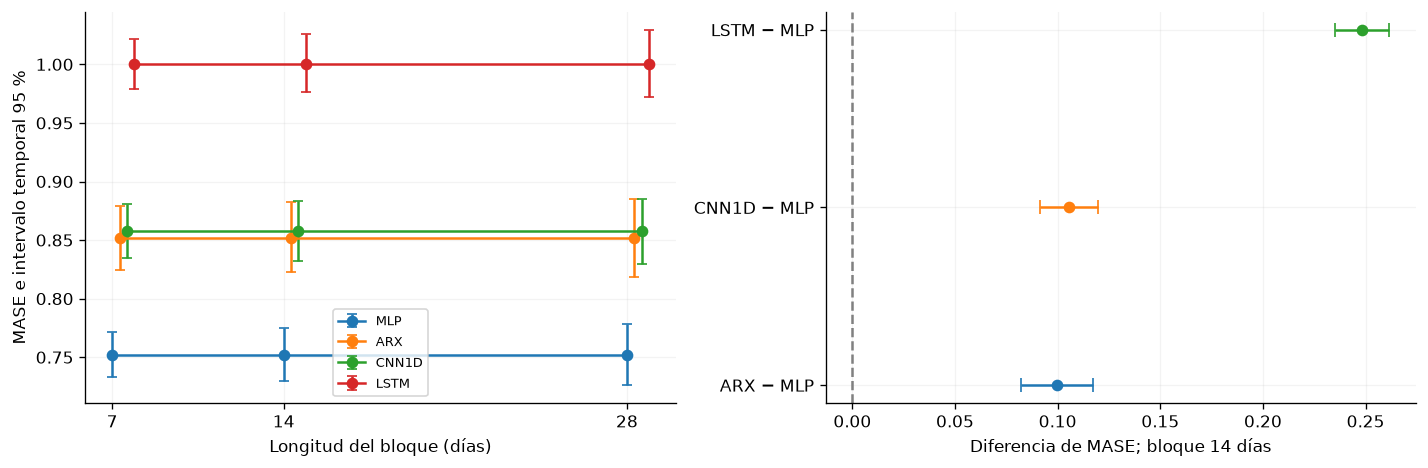

In [3]:
perdidas=np.stack([loss_d[m] for m in modelos],axis=1)
def bootstrap_temporal(valores,bloque,B=10000,semilla=11038):
    rng=np.random.default_rng(semilla);n=len(valores);salida=np.zeros((B,valores.shape[1]))
    for anio in sorted(set(fechas.year)):
        v=valores[fechas.year==anio];a=len(v);cantidad=int(np.ceil(a/bloque))
        for inicio in range(0,B,250):
            b=min(250,B-inicio);starts=rng.integers(0,a,size=(b,cantidad));ix=(starts[:,:,None]+np.arange(bloque))%a;ix=ix.reshape(b,-1)[:,:a]
            salida[inicio:inicio+b]+=v[ix].sum(axis=1)/n
    return salida
resumen=[];boot=None
for bloque in [7,14,28]:
    b=bootstrap_temporal(perdidas,bloque)
    if bloque==14:boot=b
    for j,m in enumerate(modelos):
        lo,hi=np.quantile(b[:,j],[.025,.975]);resumen.append({'modelo':m,'bloque':bloque,'MASE':perdidas[:,j].mean(),'IC95_inf':lo,'IC95_sup':hi})
intervalos=pd.DataFrame(resumen);intervalos.to_csv(OUT/'intervalos_temporales.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for i,m in enumerate(modelos):
    q=intervalos.loc[intervalos.modelo==m];axes[0].errorbar(q.bloque+.3*i,q.MASE,yerr=[q.MASE-q.IC95_inf,q.IC95_sup-q.MASE],marker='o',capsize=3,label=etiquetas[m])
for i,m in enumerate(modelos[1:]):
    diferencia=boot[:,modelos.index(m)]-boot[:,0];lo,hi=np.quantile(diferencia,[.025,.975]);centro=perdidas[:,modelos.index(m)].mean()-perdidas[:,0].mean();axes[1].errorbar(centro,i,xerr=[[centro-lo],[hi-centro]],fmt='o',capsize=4)
axes[0].set(xticks=[7,14,28],xlabel='Longitud del bloque (días)',ylabel='MASE e intervalo temporal 95 %');axes[0].legend(fontsize=8)
axes[1].axvline(0,color='grey',ls='--');axes[1].set(yticks=range(3),yticklabels=[etiquetas[m]+' − MLP' for m in modelos[1:]],xlabel='Diferencia de MASE; bloque 14 días')
fig.tight_layout();display(fig);plt.close(fig)


Los intervalos temporales incorporan días difíciles compartidos por los modelos y difieren de los intervalos entre semillas. Las diferencias positivas indican mayor pérdida que MLP bajo el remuestreo utilizado. La sensibilidad al tamaño de bloque permite valorar cuánto cambia la incertidumbre al conservar más dependencia; estos intervalos exploratorios no demuestran superioridad confirmatoria ni equivalencia.

## Contrastes de pérdida por horizonte

Diebold–Mariano utiliza diferencias diarias de pérdida absoluta para cada hora, con covarianza HAC Bartlett de 14 rezagos y corrección HLN con h=1 origen diario no solapado. Holm se aplica por separado a los 72 contrastes neuronales y los 72 contrastes contra ARX. Los valores p se conservan como diagnósticos exploratorios.

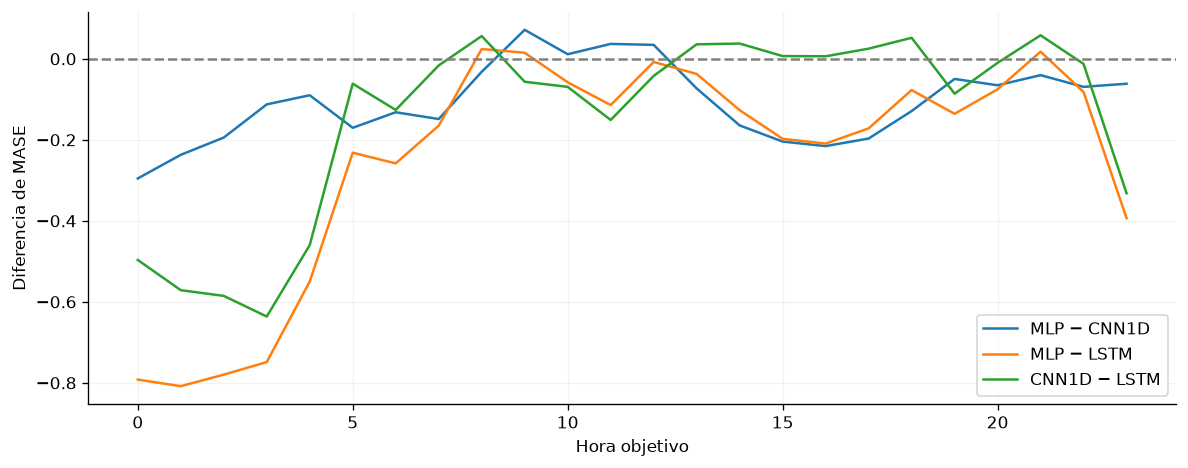

In [4]:
def dm_hln(d,rezagos=14):
    d=np.asarray(d,dtype=float);n=len(d);z=d-d.mean();long_run=np.dot(z,z)/n
    for k in range(1,rezagos+1):long_run+=2*(1-k/(rezagos+1))*np.dot(z[k:],z[:-k])/n
    estadistico=d.mean()/np.sqrt(max(long_run,1e-20)/n)*np.sqrt((n-1)/n)
    return estadistico,2*stats.t.sf(abs(estadistico),n-1)
contrastes=[]
for familia,pares in [('Redes',list(itertools.combinations(neuronales,2))),('Redes frente a ARX',[(m,'arx_lineal') for m in neuronales])]:
    temp=[]
    for a,b in pares:
        for h in range(24):
            d=loss_h[a][:,h]-loss_h[b][:,h];t,p=dm_hln(d);temp.append(dict(familia=familia,a=a,b=b,hora=h,diferencia_MASE=d.mean(),DM_HLN=t,p=p))
    corregidos=multipletests([r['p'] for r in temp],method='holm')[1]
    for r,p in zip(temp,corregidos):r['p_Holm']=p
    contrastes.extend(temp)
dm=pd.DataFrame(contrastes);dm.to_csv(OUT/'DM_24_horizontes.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4))
for a,b in itertools.combinations(neuronales,2):
    q=dm.loc[(dm.a==a)&(dm.b==b)];ax.plot(q.hora,q.diferencia_MASE,label=etiquetas[a]+' − '+etiquetas[b])
ax.axhline(0,color='grey',ls='--');ax.set(xlabel='Hora objetivo',ylabel='Diferencia de MASE');ax.legend();fig.tight_layout();display(fig);plt.close(fig)

Las curvas permiten identificar horas en las que cambia la distancia de error entre redes; por debajo de cero la primera familia presenta menor pérdida. El promedio global puede ocultar diferencias localizadas. La [tabla de contrastes](_static/resultados/DM_24_horizontes.csv) conserva estadísticos, valores p y corrección de multiplicidad, sin convertir el análisis exploratorio en una afirmación confirmatoria.

## Rangos y variabilidad entre inicializaciones

Los rangos se calculan dentro de cada semilla. La descomposición separa diferencias descriptivas entre fechas e inicializaciones; no supone que las semillas sean mercados o periodos independientes.

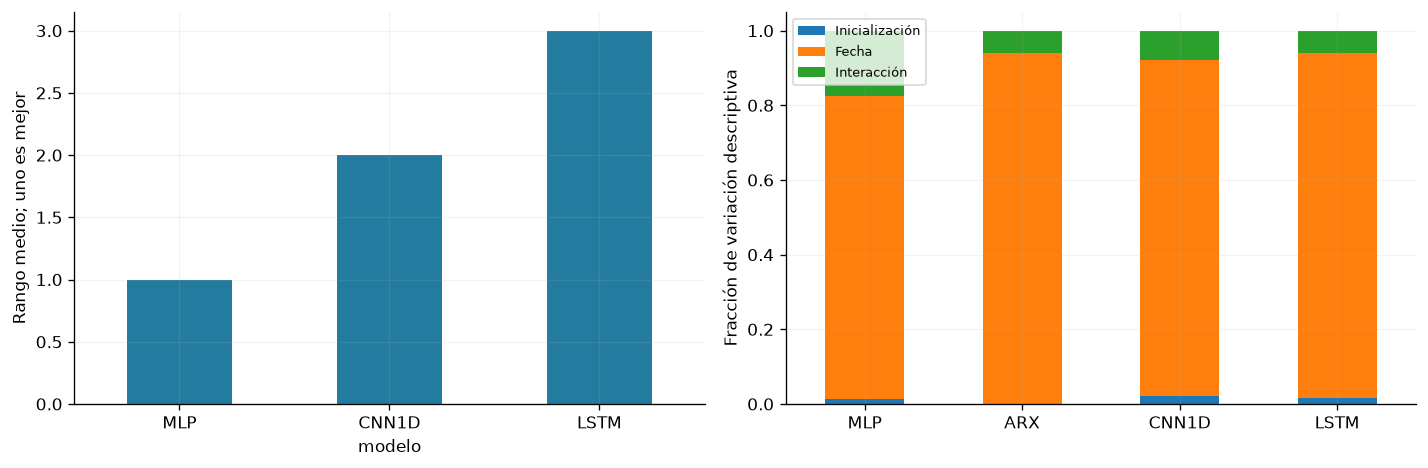

In [5]:
matriz=calculadas.pivot(index='semilla',columns='modelo',values='MASE').reindex(columns=neuronales);rangos=matriz.rank(axis=1).mean()
componentes=[]
for m in modelos:
    valores=np.abs(pred[m]-y[None,:,:]).mean(axis=2)/escala;media=valores.mean();por_semilla=np.mean((valores.mean(axis=1)-media)**2);por_dia=np.mean((valores.mean(axis=0)-media)**2);interaccion=np.mean((valores-valores.mean(axis=1)[:,None]-valores.mean(axis=0)[None,:]+media)**2)
    componentes.append({'modelo':m,'Inicialización':por_semilla,'Fecha':por_dia,'Interacción':interaccion})
fig,axes=plt.subplots(1,2,figsize=(12,4));rangos.rename(index=etiquetas).plot.bar(ax=axes[0],rot=0,color='#247ba0');axes[0].set_ylabel('Rango medio; uno es mejor')
comp=pd.DataFrame(componentes).set_index('modelo');comp.index=comp.index.map(etiquetas);comp.div(comp.sum(axis=1),axis=0).plot.bar(stacked=True,ax=axes[1],rot=0);axes[1].set(ylabel='Fracción de variación descriptiva',xlabel='');axes[1].legend(fontsize=8)
fig.tight_layout();display(fig);plt.close(fig)
pd.DataFrame(componentes).to_csv(OUT/'componentes_variacion.csv',index=False);rangos.to_csv(OUT/'rangos_semillas.csv')

El rango resume consistencia ordinal entre las cinco inicializaciones y descarta la magnitud de las diferencias. La componente de fecha muestra variación común a los pronósticos de un mismo día; la interacción recoge sensibilidad de cada inicialización a días concretos. Estas componentes describen los errores observados y no equivalen a efectos causales o a una estimación de potencia.

## Residuos y estructura remanente

Se utiliza la semilla 1000 y se promedian residuos horarios dentro de cada día. Ljung–Box examina autocorrelación; ARCH, variación condicional; BDS, dependencia incompatible con una secuencia i.i.d. BDS no aísla no linealidad cuando existe memoria.

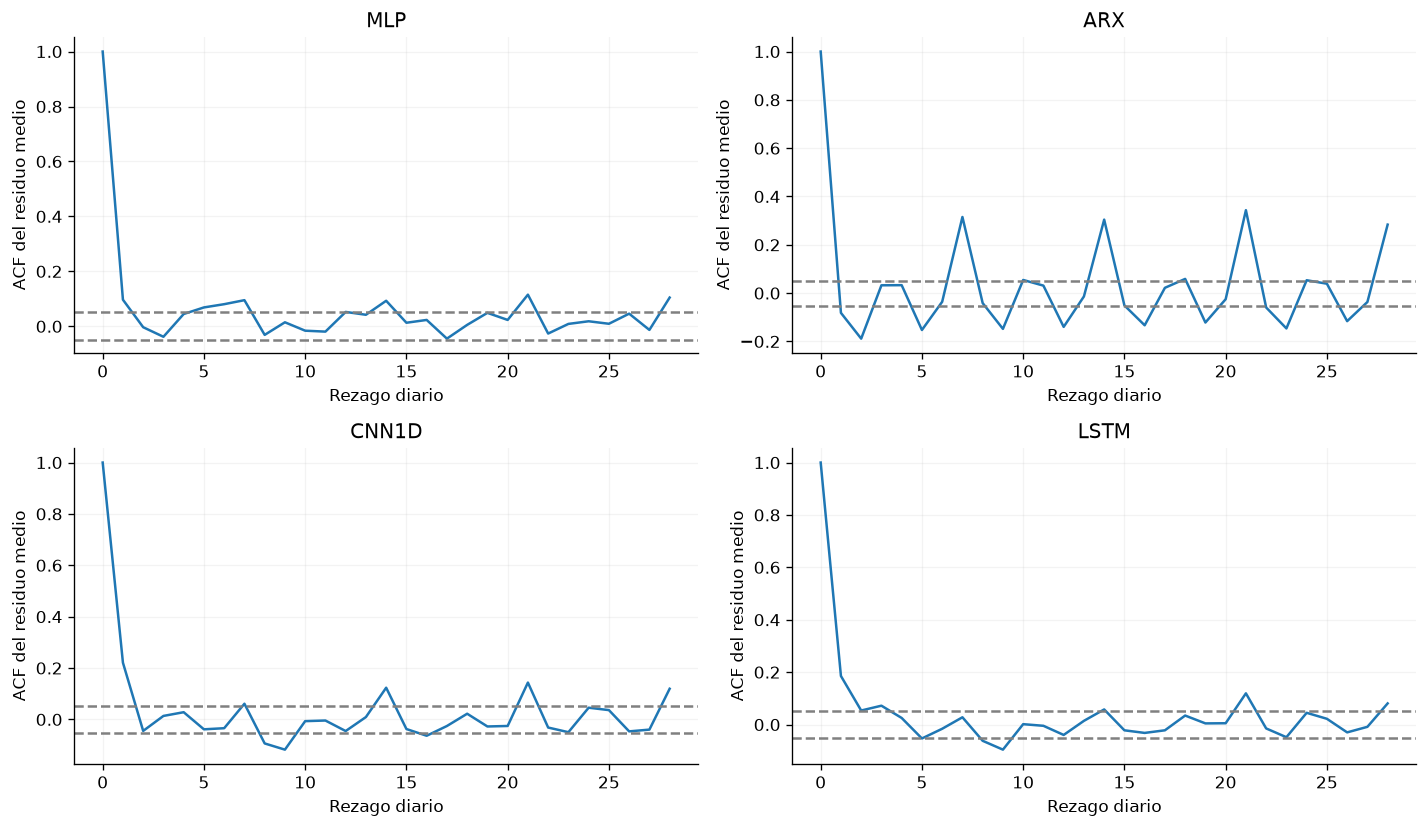

In [6]:
from statsmodels.tsa.stattools import acf,bds
from statsmodels.stats.diagnostic import acorr_ljungbox,acorr_lm
fig,axes=plt.subplots(2,2,figsize=(12,7));diagnosticos=[]
for ax,m in zip(axes.ravel(),modelos):
    r=residuos[m].mean(axis=1)/1e3;ax.plot(range(29),acf(r,nlags=28,fft=True));ax.axhline(1.96/np.sqrt(len(r)),color='grey',ls='--');ax.axhline(-1.96/np.sqrt(len(r)),color='grey',ls='--');ax.set(title=etiquetas[m],xlabel='Rezago diario',ylabel='ACF del residuo medio')
    lb=acorr_ljungbox(r,lags=[7,14,28],return_df=True)
    for k,row in lb.iterrows():diagnosticos.append({'modelo':m,'prueba':'Ljung–Box','rezago':int(k),'estadistico':row.lb_stat,'p':row.lb_pvalue})
    a=acorr_lm(r**2,nlags=7,ddof=0,result_object=False);diagnosticos.append({'modelo':m,'prueba':'ARCH','rezago':7,'estadistico':a[0],'p':a[1]})
    z,p=bds(r[-1000:],max_dim=2);diagnosticos.append({'modelo':m,'prueba':'BDS','rezago':2,'estadistico':float(z),'p':float(p)})
fig.tight_layout();display(fig);plt.close(fig)
diagnosticos=pd.DataFrame(diagnosticos);diagnosticos['p_Holm']=multipletests(diagnosticos.p,method='holm')[1];diagnosticos.to_csv(OUT/'diagnosticos_residuos.csv',index=False)

La autocorrelación residual identifica estructura temporal que las predicciones no absorben. Las bandas son una referencia descriptiva de ruido blanco; el diagnóstico formal conserva Ljung–Box, ARCH y BDS con Holm entre 20 contrastes. La persistencia de memoria justifica conservar bloques temporales al resumir incertidumbre y limita una interpretación i.i.d. de los errores.

## Comparaciones pareadas entre inicializaciones

Se comparan las mismas cinco semillas. Shapiro–Wilk y Q–Q describen diferencias; con n=5 no rechazar normalidad no la demuestra. Se presenta t pareada como aproximación paramétrica, Wilcoxon bilateral exacto como sensibilidad y bootstrap empírico exhaustivo de los 5⁵ remuestreos posibles. Holm corrige separadamente las tres comparaciones de cada método. Cohen dz utiliza la DE de diferencias pareadas.

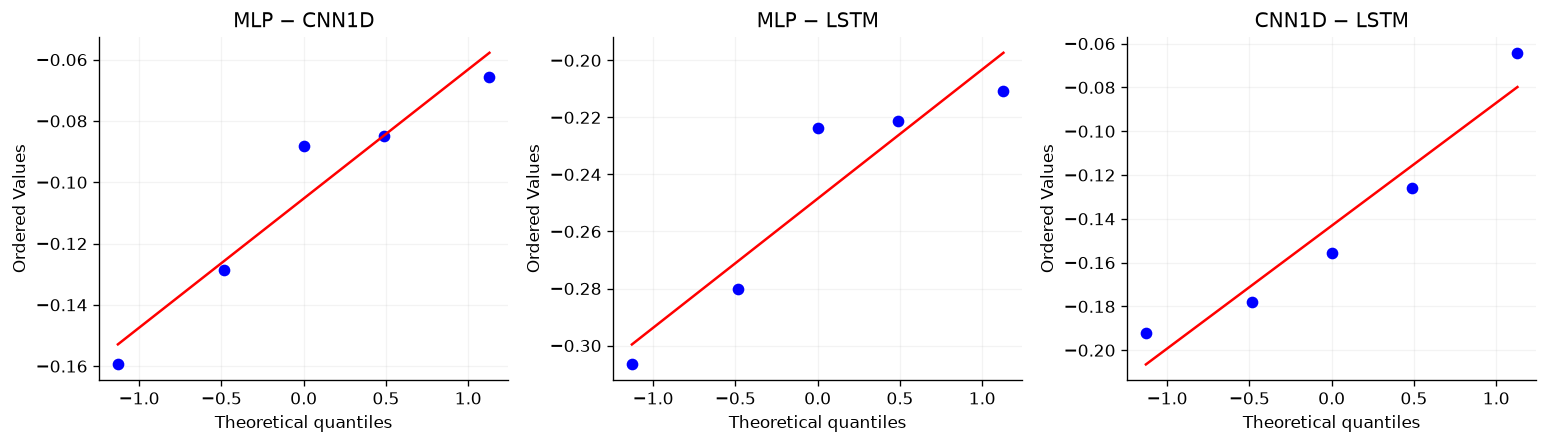

In [7]:
pares=[];qqfig,qqaxes=plt.subplots(1,3,figsize=(13,3.8));ix_boot=np.asarray(list(itertools.product(range(5),repeat=5)))
for ax,(a,b) in zip(qqaxes,itertools.combinations(neuronales,2)):
    aa=calculadas.loc[calculadas.modelo==a].sort_values('semilla').set_index('semilla')
    bb=calculadas.loc[calculadas.modelo==b].sort_values('semilla').set_index('semilla')
    assert aa.index.equals(bb.index)
    d=(aa.MASE-bb.MASE).to_numpy();sd=d.std(ddof=1);se=sd/np.sqrt(5)
    t=stats.ttest_rel(aa.MASE,bb.MASE);w=stats.wilcoxon(d,method='exact');sw=stats.shapiro(d)
    ci=stats.t.ppf(.975,4)*se;bs=d[ix_boot].mean(axis=1)
    stats.probplot(d,dist='norm',plot=ax);ax.set_title(etiquetas[a]+' − '+etiquetas[b])
    pares.append(dict(a=a,b=b,comparacion=etiquetas[a]+' − '+etiquetas[b],diferencia_MASE=d.mean(),IC95_t_inf=d.mean()-ci,IC95_t_sup=d.mean()+ci,
        IC95_boot_inf=np.quantile(bs,.025),IC95_boot_sup=np.quantile(bs,.975),Shapiro_W=sw.statistic,Shapiro_p=sw.pvalue,t=t.statistic,p_t=t.pvalue,
        Wilcoxon_W=w.statistic,p_Wilcoxon=w.pvalue,Cohen_dz=d.mean()/sd,
        reduccion_MAE_a_vs_b_pct=100*(1-aa.MAE.mean()/bb.MAE.mean()),reduccion_RMSE_a_vs_b_pct=100*(1-aa.RMSE.mean()/bb.RMSE.mean())))
qqfig.tight_layout();display(qqfig);plt.close(qqfig)
comparaciones=pd.DataFrame(pares)
comparaciones['p_t_Holm']=multipletests(comparaciones.p_t,method='holm')[1]
comparaciones['p_Wilcoxon_Holm']=multipletests(comparaciones.p_Wilcoxon,method='holm')[1]
comparaciones.to_csv(OUT/'comparaciones_pareadas.csv',index=False)


Los Q–Q permiten detectar desviaciones visibles, pero cinco puntos ofrecen poca resolución. La independencia relevante es entre inicializaciones condicionadas a las mismas fechas; no implica independencia temporal. Los intervalos bootstrap describen la muestra empírica de cinco pares y no compensan su tamaño reducido.

In [8]:
display(comparaciones[['comparacion','diferencia_MASE','IC95_t_inf','IC95_t_sup','IC95_boot_inf','IC95_boot_sup','Shapiro_p','p_t_Holm','p_Wilcoxon_Holm','Cohen_dz']].style.format({'Shapiro_p':formato_p,'p_t_Holm':formato_p,'p_Wilcoxon_Holm':formato_p},precision=5))

,comparacion,diferencia_MASE,IC95_t_inf,IC95_t_sup,IC95_boot_inf,IC95_boot_sup,Shapiro_p,p_t_Holm,p_Wilcoxon_Holm,Cohen_dz
0,MLP − CNN1D,-0.10532,-0.15248,-0.05817,-0.13834,-0.07777,0.551,0.00643,0.188,-2.77354
1,MLP − LSTM,-0.24848,-0.30101,-0.19595,-0.28425,-0.21755,0.188,0.000582,0.188,-5.87309
2,CNN1D − LSTM,-0.14316,-0.20610,-0.08021,-0.17910,-0.10081,0.555,0.00643,0.188,-2.82400


Las tres t pareadas con Holm producen p entre 0,000582 y 0,006434, mientras Wilcoxon ajustado es 0,1875 en las tres parejas. La t aporta evidencia condicional bajo su aproximación; la diferencia entre métodos refleja su resolución y supuestos. Una diferencia negativa favorece al primer modelo. Wilcoxon bilateral exacto tiene p mínimo 0,0625 con cinco pares sin ceros ni empates: su falta de rechazo no es evidencia de igualdad. La t y el bootstrap deben leerse con sus supuestos y junto con la evaluación temporal. [Resultados completos, incluidos p sin ajustar](_static/resultados/comparaciones_pareadas.csv).

## Contraste global y comparación de rangos

Friedman se evalúa por enumeración de las 6⁵ permutaciones de etiquetas dentro de semilla, evitando depender sólo de su aproximación asintótica. Nemenyi se informa como post-hoc aproximado; el rango studentizado incorpora la comparación conjunta de las tres familias.

In [9]:
matriz=calculadas.pivot(index='semilla',columns='modelo',values='MASE').reindex(columns=neuronales)
rk=stats.rankdata(matriz.to_numpy(),axis=1);n,k=rk.shape
assert all(len(np.unique(row))==k for row in matriz.to_numpy())
Q=12*n/(k*(k+1))*np.sum(rk.mean(axis=0)**2)-3*n*(k+1)
permutaciones=np.asarray(list(itertools.permutations(range(k))))
combinaciones=np.asarray(list(itertools.product(range(len(permutaciones)),repeat=n)))
sumas=np.zeros((len(combinaciones),k))
for i in range(n):sumas+=rk[i][permutaciones[combinaciones[:,i]]]
Q_nulo=12*n/(k*(k+1))*np.sum((sumas/n)**2,axis=1)-3*n*(k+1)
p_friedman=float(np.mean(Q_nulo>=Q-1e-12))
friedman=pd.DataFrame([{'Q':Q,'p_exacto':p_friedman,'permutaciones':len(Q_nulo),'bloques_semilla':n}]);display(friedman)
friedman.to_csv(OUT/'friedman_exacto.csv',index=False)
nemenyi=[]
for ia,ib in itertools.combinations(range(k),2):
    diferencia=abs(rk.mean(axis=0)[ia]-rk.mean(axis=0)[ib]);q=diferencia/np.sqrt(k*(k+1)/(6*n))
    nemenyi.append({'comparacion':etiquetas[neuronales[ia]]+' − '+etiquetas[neuronales[ib]],'diferencia_rangos':diferencia,'p_Nemenyi_aprox':stats.studentized_range.sf(q*np.sqrt(2),k,np.inf)})
nemenyi=pd.DataFrame(nemenyi);display(nemenyi.round(5));nemenyi.to_csv(OUT/'nemenyi.csv',index=False)


,Q,p_exacto,permutaciones,bloques_semilla
0,10.0,0.000772,7776,5


,comparacion,diferencia_rangos,p_Nemenyi_aprox
0,MLP − CNN1D,1.0,0.25378
1,MLP − LSTM,2.0,0.00446
2,CNN1D − LSTM,1.0,0.25378


Friedman obtiene Q=10 y p exacto=0,000772. Nemenyi aproximado produce p=0,00446 para MLP–LSTM y 0,25378 para las otras dos parejas. Contrasta diferencias de rangos, no igualdad de MAE promedio. Un resultado global no identifica por sí solo qué parejas difieren. Nemenyi es aproximado con cinco bloques y no reemplaza las diferencias pareadas y sus intervalos. [Friedman](_static/resultados/friedman_exacto.csv), [Nemenyi](_static/resultados/nemenyi.csv).

## Equivalencia y reducciones relativas

TOST contrasta θ_AB=(μ_A−μ_B)/μ_MLP dentro de [−0,03;0,03], siendo μ_MLP positiva. Se aplican dos t unilaterales a las combinaciones pareadas d+0,03·MLP y d−0,03·MLP; así se incorpora la incertidumbre de la referencia, sin sustituirla por un margen absoluto estimado en prueba. Se reportan IC90 % de Fieller individuales y p con Holm, por separado entre redes y frente a ARX. La equivalencia requiere rechazar ambas hipótesis unilaterales; no se deriva de medias próximas. Las reducciones de MAE y RMSE se calculan respecto a la mejor y la peor red del benchmark.

In [10]:
# El único margen es relativo a la media poblacional de MLP: ±3 %.
# theta_AB = (E[MASE_A] - E[MASE_B]) / E[MASE_MLP].
delta_rel=.03;equivalencias=[]
mm=calculadas.loc[calculadas.modelo=='mlp'].sort_values('semilla').MASE.to_numpy()
def fieller_pareado(numerador,denominador,confianza=.90):
    n=len(numerador);v=np.cov(numerador,denominador,ddof=1)/n
    x=denominador.mean();y=numerador.mean();q=stats.t.ppf((1+confianza)/2,n-1)**2
    a=x*x-q*v[1,1];b=-2*x*y+2*q*v[0,1];c=y*y-q*v[0,0]
    if a<=0 or b*b-4*a*c<0:return -np.inf,np.inf
    raiz=np.sqrt(b*b-4*a*c)
    return (-b-raiz)/(2*a),(-b+raiz)/(2*a)
for familia,lista in [('Redes',list(itertools.combinations(neuronales,2))),('Redes frente a ARX',[(m,'arx_lineal') for m in neuronales])]:
    filas=[]
    for a,b in lista:
        aa=calculadas.loc[calculadas.modelo==a].sort_values('semilla').MASE.to_numpy();bb=calculadas.loc[calculadas.modelo==b].sort_values('semilla').MASE.to_numpy()
        d=aa-bb
        # H0 inferior: E[d] <= -0.03 E[MLP]; H0 superior: E[d] >= +0.03 E[MLP].
        inferior=stats.ttest_1samp(d+delta_rel*mm,0,alternative='greater')
        superior=stats.ttest_1samp(d-delta_rel*mm,0,alternative='less')
        p=max(inferior.pvalue,superior.pvalue);lo,hi=fieller_pareado(d,mm)
        assert (lo>-delta_rel and hi<delta_rel)==bool(p<.05)
        filas.append({'familia':familia,'comparacion':etiquetas[a]+' − '+etiquetas[b],
            'diferencia_rel_pct':100*d.mean()/mm.mean(),'margen_rel_pct':100*delta_rel,
            'IC90_Fieller_inf_pct':100*lo,'IC90_Fieller_sup_pct':100*hi,
            'p_TOST_inferior':inferior.pvalue,'p_TOST_superior':superior.pvalue,'p_TOST':p})
    adj=multipletests([f['p_TOST'] for f in filas],method='holm')[1]
    for f,p in zip(filas,adj):f['p_TOST_Holm']=p;f['equivalencia_Holm_005']=bool(p<.05)
    equivalencias.extend(filas)
equivalencias=pd.DataFrame(equivalencias);display(equivalencias.round(5));equivalencias.to_csv(OUT/'equivalencia_TOST.csv',index=False)
p_equiv_arx_cnn=float(equivalencias.loc[equivalencias.comparacion=='CNN1D − ARX','p_TOST_Holm'].iloc[0])
relativas=[]
b=benchmark.set_index('familia');mejor_red=b.loc[neuronales].MASE.idxmin();peor_red=b.loc[neuronales].MASE.idxmax()
for m in neuronales:
    relativas.append({'modelo':etiquetas[m],'reduccion_MAE_vs_peor_pct':100*(1-b.loc[m,'MAE_kWh']/b.loc[peor_red,'MAE_kWh']),
        'reduccion_RMSE_vs_peor_pct':100*(1-b.loc[m,'RMSE_kWh']/b.loc[peor_red,'RMSE_kWh']),
        'reduccion_MAE_vs_mejor_pct':100*(1-b.loc[m,'MAE_kWh']/b.loc[mejor_red,'MAE_kWh']),
        'reduccion_RMSE_vs_mejor_pct':100*(1-b.loc[m,'RMSE_kWh']/b.loc[mejor_red,'RMSE_kWh'])})
relativas=pd.DataFrame(relativas);display(relativas.round(3));relativas.to_csv(OUT/'reducciones_relativas.csv',index=False)
umbral_mase=.97*float(mejor.MASE);umbral_mae=umbral_mase*escala


,familia,comparacion,diferencia_rel_pct,margen_rel_pct,IC90_Fieller_inf_pct,IC90_Fieller_sup_pct,p_TOST_inferior,p_TOST_superior,p_TOST,p_TOST_Holm,equivalencia_Holm_005
0,Redes,MLP − CNN1D,-14.00555,3.0,-18.64054,-9.30831,0.99603,0.00087,0.99603,1.00000,False
1,Redes,MLP − LSTM,-33.04162,3.0,-39.34105,-27.10308,0.99985,0.00007,0.99985,1.00000,False
2,Redes,CNN1D − LSTM,-19.03608,3.0,-26.20530,-12.28998,0.99687,0.00089,0.99687,1.00000,False
3,Redes frente a ARX,MLP − ARX,-13.25137,3.0,-19.14936,-7.94971,0.99385,0.00092,0.99385,1.00000,False
4,Redes frente a ARX,CNN1D − ARX,0.75418,3.0,-7.48954,8.33933,0.18827,0.28632,0.28632,0.85897,False
5,Redes frente a ARX,LSTM − ARX,19.79026,3.0,14.84791,24.49716,0.00045,0.99875,0.99875,1.00000,False


,modelo,reduccion_MAE_vs_peor_pct,reduccion_RMSE_vs_peor_pct,reduccion_MAE_vs_mejor_pct,reduccion_RMSE_vs_mejor_pct
0,MLP,24.836,22.583,0.000,0.000
1,CNN1D,14.308,11.604,-14.006,-14.182
2,LSTM,0.000,0.000,-33.042,-29.171


Para CNN1D frente a ARX, TOST produce p ajustado=0.8590; no se establece equivalencia al nivel 0,05 bajo el margen relativo del 3 % y los supuestos paramétricos. El umbral práctico para un modelo avanzado es MASE < 0.729461, equivalente a MAE < 157,284.91 kWh con la escala fija. Cruzar ese umbral no sustituye un intervalo o contraste de superioridad. [TOST](_static/resultados/equivalencia_TOST.csv), [reducciones relativas](_static/resultados/reducciones_relativas.csv).

## Contrastes temporales globales y referencias estacionales

Se reconstruyen ingenuos diario y semanal con la misma disponibilidad al origen y se verifican sus métricas publicadas. El bootstrap circular de 14 días utiliza índices comunes para todos los métodos. Se reportan DM–HLN global, bootstrap centrado y Holm en tres familias: redes, redes frente a ARX y modelos frente a los dos ingenuos. Los 192 contrastes horarios frente a ingenuos forman una familia separada.

In [11]:
observado=pd.read_parquet(ROOT/'data/processed/panel_horario.parquet',columns=['y_demanda_real_kwh'])['y_demanda_real_kwh']
tiempos=pd.DatetimeIndex([d+pd.Timedelta(hours=h) for d in fechas for h in range(24)])
for nombre,lag in [('ingenuo_24h',24),('ingenuo_168h',168)]:
    dias=lag//24
    # El rezago publicado de demanda impide usar t0-1h; retrasar referencias intradía no disponibles.
    base=np.asarray([observado.loc[t-pd.Timedelta(hours=lag if h<=lag-2 else 2*lag)] for d in fechas for h,t in enumerate(pd.date_range(d,periods=24,freq='h'))]).reshape(y.shape)
    abs_error=np.abs(base-y)/escala
    assert np.isclose(abs_error.mean(),referencias[nombre]['MASE'],rtol=2e-6),(nombre,abs_error.mean())
    loss_h[nombre]=abs_error;loss_d[nombre]=abs_error.mean(axis=1)
todos=modelos+['ingenuo_24h','ingenuo_168h'];perdidas_todas=np.stack([loss_d[m] for m in todos],axis=1)
boot_todas=bootstrap_temporal(perdidas_todas,14)
contrastes_globales=[];contrastes_ref=[]
familias=[('Redes',list(itertools.combinations(neuronales,2))),('Redes frente a ARX',[(m,'arx_lineal') for m in neuronales]),('Frente a ingenuos',[(m,r) for m in modelos for r in ['ingenuo_24h','ingenuo_168h']])]
for familia,lista in familias:
    filas=[];horas=[]
    for a,b in lista:
        d=loss_d[a]-loss_d[b];j=todos.index(a);l=todos.index(b);distrib=boot_todas[:,j]-boot_todas[:,l]
        lo,hi=np.quantile(distrib,[.025,.975]);t,p=dm_hln(d)
        p_boot=(1+np.sum(np.abs(distrib-distrib.mean())>=abs(d.mean())))/(len(distrib)+1)
        filas.append({'familia':familia,'comparacion':etiquetas[a]+' − '+etiquetas[b],'diferencia_MASE':d.mean(),'IC95_boot_inf':lo,'IC95_boot_sup':hi,'DM_HLN':t,'p_DM':p,'p_boot':p_boot,'reduccion_MAE_pct':100*(1-loss_d[a].mean()/loss_d[b].mean())})
        if familia=='Frente a ingenuos':
            for h in range(24):
                t,p=dm_hln(loss_h[a][:,h]-loss_h[b][:,h]);horas.append({'familia':familia,'a':a,'b':b,'hora':h,'diferencia_MASE':(loss_h[a][:,h]-loss_h[b][:,h]).mean(),'DM_HLN':t,'p':p})
    for campo in ['p_DM','p_boot']:
        ajustados=multipletests([f[campo] for f in filas],method='holm')[1]
        for f,p in zip(filas,ajustados):f[campo+'_Holm']=p
    contrastes_globales.extend(filas)
    if horas:
        adj=multipletests([f['p'] for f in horas],method='holm')[1]
        for f,p in zip(horas,adj):f['p_Holm']=p
        contrastes_ref.extend(horas)
globales=pd.DataFrame(contrastes_globales);display(globales[['comparacion','diferencia_MASE','IC95_boot_inf','IC95_boot_sup','p_DM_Holm','p_boot_Holm']].style.format({'p_DM_Holm':formato_p,'p_boot_Holm':formato_p},precision=5))
globales.to_csv(OUT/'contrastes_temporales_globales.csv',index=False)
pd.concat([dm,pd.DataFrame(contrastes_ref)],ignore_index=True).to_csv(OUT/'DM_24_horizontes.csv',index=False)
intervalos.to_csv(OUT/'intervalos_temporales.csv',index=False)


,comparacion,diferencia_MASE,IC95_boot_inf,IC95_boot_sup,p_DM_Holm,p_boot_Holm
0,MLP − CNN1D,-0.10532,-0.11952,-0.09127,6.39e-44,0.0003
1,MLP − LSTM,-0.24848,-0.26148,-0.23530,1.76e-113,0.0003
2,CNN1D − LSTM,-0.14316,-0.15670,-0.12980,3.33e-41,0.0003
3,MLP − ARX,-0.09965,-0.11743,-0.08232,3.87e-26,0.0003
4,CNN1D − ARX,0.00567,-0.01092,0.02250,0.508,0.501
5,LSTM − ARX,0.14883,0.13110,0.16565,1.65e-32,0.0003
6,MLP − Ingenuo diario,-1.32470,-1.36384,-1.28699,<1e-300,0.0008
7,MLP − Ingenuo semanal,-0.60288,-0.69951,-0.51002,8.44e-32,0.0008
8,ARX − Ingenuo diario,-1.22505,-1.26684,-1.18406,<1e-300,0.0008
9,ARX − Ingenuo semanal,-0.50323,-0.59792,-0.41200,6.58e-24,0.0008


Los intervalos describen diferencias temporales de pérdida promediada entre inicializaciones. Una reducción positiva favorece al primer método; una diferencia negativa de MASE también lo favorece. Los resultados frente a ingenuos evalúan su utilidad como referencia sobre los mismos días. [Contrastes globales](_static/resultados/contrastes_temporales_globales.csv), [DM de todas las horas](_static/resultados/DM_24_horizontes.csv), [sensibilidad al bloque](_static/resultados/intervalos_temporales.csv).

## Impacto de valores atípicos sobre el error e identidad de prueba

Se fijan umbrales de Tukey, Q1−1,5IQR y Q3+1,5IQR, sobre el logaritmo de la razón entre demanda y su valor 168 horas antes, usando sólo 2000–2017. Se aplican a las etiquetas de prueba como diagnóstico de segmentos. Los modelos y sus predicciones permanecen congelados; excluir horas en esta tabla es una sensibilidad del cálculo del error, no un ajuste del modelo.

In [12]:
serie=observado
desarrollo=serie.loc[serie.index<'2018-01-01'];log_razon=np.log(desarrollo/desarrollo.shift(168)).dropna()
q1,q3=log_razon.quantile([.25,.75]);iqr=q3-q1;limites=(q1-1.5*iqr,q3+1.5*iqr)
referencia_semana=observado.reindex(tiempos-pd.Timedelta(hours=168)).to_numpy().reshape(y.shape)
razon_objetivo=np.log(y/referencia_semana);atipico=(razon_objetivo<limites[0])|(razon_objetivo>limites[1])
impacto=[]
for m in modelos:
    errores=np.abs(pred[m]-y[None,:,:]);e=errores.mean(axis=0)
    impacto.append({'modelo':etiquetas[m],'horas_atipicas':int(atipico.sum()),'MAE_atipico_kWh':e[atipico].mean(),'MAE_resto_kWh':e[~atipico].mean(),
        'aporte_error_atipico_pct':100*e[atipico].sum()/e.sum(),'cambio_MAE_al_excluir_pct':100*(e[~atipico].mean()/e.mean()-1)})
impacto=pd.DataFrame(impacto);display(impacto.round(3));impacto.to_csv(OUT/'impacto_atipicos_error.csv',index=False)
porcentaje_atipico=100*atipico.mean()
digest=hashlib.sha256();digest.update(b'SIN-demand-test-v1\n');digest.update(np.asarray(origen,dtype='<i8').tobytes());digest.update(np.asarray(y,dtype='<f8').tobytes())
hash_prueba=digest.hexdigest()
(OUT/'huella_prueba.json').write_text(json.dumps({'sha256':hash_prueba,'commit':SHA,'origenes':1461,'horizonte':24,'inicio':str(fechas.min()),'fin':str(fechas.max()),
    'serializacion':'cabecera UTF-8 SIN-demand-test-v1 y LF; orígenes UTC int64 little-endian; etiquetas float64 little-endian, orden C','fecha_calculo':pd.Timestamp.now(tz='America/Bogota').isoformat()},ensure_ascii=False,indent=2),encoding='utf-8')


Out[0]: 448


,modelo,horas_atipicas,MAE_atipico_kWh,MAE_resto_kWh,aporte_error_atipico_pct,cambio_MAE_al_excluir_pct
0,MLP,2520,194785.909,159622.229,8.633,-1.559
1,ARX,2520,248818.783,178589.098,9.738,-2.749
2,CNN1D,2520,264847.422,178665.536,10.297,-3.351
3,LSTM,2520,262977.249,212067.367,8.761,-1.696


Los umbrales marcan el 7.19 % de las horas evaluadas. En MLP concentran el 8,63 % del error absoluto; excluirlas reduce su MAE un 1,56 %. Para CNN1D la reducción descriptiva es 3,35 %. El benchmark conserva todas las horas. Un valor extremo relativo puede corresponder a un festivo o cambio real de actividad, sin ser un error de medición. [Sensibilidad del error](_static/resultados/impacto_atipicos_error.csv).

**SHA-256 de orígenes y etiquetas de prueba:** `595f00dd186280542cfd7fed9a580ebe1b19c8cc4e0e742ef12e2e6d2eb0f49a`. La especificación canónica y la fecha de cálculo están en la [huella del conjunto](_static/resultados/huella_prueba.json).

## Resultados numéricos y archivos

Además de los contrastes, se conservan [intervalos temporales](_static/resultados/intervalos_temporales.csv), [errores por hora](_static/resultados/errores_24_horizontes.csv), [errores por segmento](_static/resultados/errores_segmentos.csv), [residuos y Holm](_static/resultados/diagnosticos_residuos.csv) y [componentes de variabilidad](_static/resultados/componentes_variacion.csv).

In [13]:
display(intervalos.loc[intervalos.bloque==14].round(5));display(diagnosticos[['modelo','prueba','rezago','estadistico','p','p_Holm']].style.format({'p':formato_p,'p_Holm':formato_p},precision=5))

,modelo,bloque,MASE,IC95_inf,IC95_sup
4,mlp,14,0.75202,0.73007,0.77490
5,arx_lineal,14,0.85168,0.82271,0.88223
6,cnn1d,14,0.85735,0.83235,0.88308
7,lstm,14,1.00050,0.97624,1.02576


,modelo,prueba,rezago,estadistico,p,p_Holm
0,mlp,Ljung–Box,7,48.63960,2.67e-08,2.14e-07
1,mlp,Ljung–Box,14,70.74618,1.41e-09,1.41e-08
2,mlp,Ljung–Box,28,120.46063,1.94e-13,2.33e-12
3,mlp,ARCH,7,38.02611,3e-06,1.5e-05
4,mlp,BDS,2,2.43238,0.015,0.03
5,arx_lineal,Ljung–Box,7,246.96732,1.22e-49,2.2e-48
6,arx_lineal,Ljung–Box,14,453.25400,7.3e-88,1.39e-86
7,arx_lineal,Ljung–Box,28,872.52320,1.17e-165,2.35e-164
8,arx_lineal,ARCH,7,44.12386,2.02e-07,1.42e-06
9,arx_lineal,BDS,2,4.95604,7.19e-07,4.32e-06


Los intervalos de 14 días son la estimación temporal principal; los otros bloques evalúan sensibilidad. Los diagnósticos de residuos examinan estructura remanente y no prueban superioridad predictiva. Los archivos completos preservan precisión numérica y valores p sin ajustar.

(importancia-variables)=
## Importancia de variables y bloques de rezagos

Se mide cuánto aumenta el error al perturbar un grupo de entradas, manteniendo los pesos y los escaladores. El análisis incluye los 1.461 orígenes diarios de 2022–2025, cuatro familias y cinco inicializaciones por familia. La demanda histórica y el calendario son las entradas de estos modelos; el clima, la hidrología y el texto no reciben puntuaciones porque no intervienen en sus pronósticos.

La [importancia por permutación](https://scikit-learn.org/stable/modules/permutation_importance.html) describe la dependencia de un modelo ajustado respecto de sus entradas. Aquí se adapta a ventanas temporales: se trasladan circularmente orígenes completos dentro de cada año, con diez desplazamientos reproducibles y una separación circular mínima de 28 días. Se conserva el orden de las horas dentro de cada bloque y se utilizan los mismos donantes para familias, semillas y grupos. Las etiquetas permanecen en sus fechas originales. Esta perturbación es un diagnóstico retrospectivo, no un pronóstico operativo ni una estimación causal.

La importancia se expresa como diferencia de MASE:

$$I_g=\frac{1}{50}\sum_{s=1}^{5}\sum_{r=1}^{10}
\frac{\operatorname{MAE}_{s,r,g}-\operatorname{MAE}_{s}}{q_{168}}.$$

Las figuras muestran el cambio porcentual respecto del MAE basal de cada modelo, equivalente al cambio relativo de MASE con el denominador fijo. Un valor positivo indica deterioro al perturbar la entrada; uno negativo indica menor error bajo esa perturbación. Las comparaciones son condicionales al modelo, al periodo y al esquema de donantes.

### Demanda y calendario

La demanda se examina como perfil normalizado y nivel medio de la ventana, tanto por separado como conjuntamente. Perturbar el nivel modifica el factor usado al restituir la salida a kWh. El calendario se transfiere simultáneamente en pasado y horizonte, conservando juntas las codificaciones de cada grupo. Se distinguen calendario completo, semana y festivos, y año y temporadas. Los grupos se solapan y sus importancias no se suman.

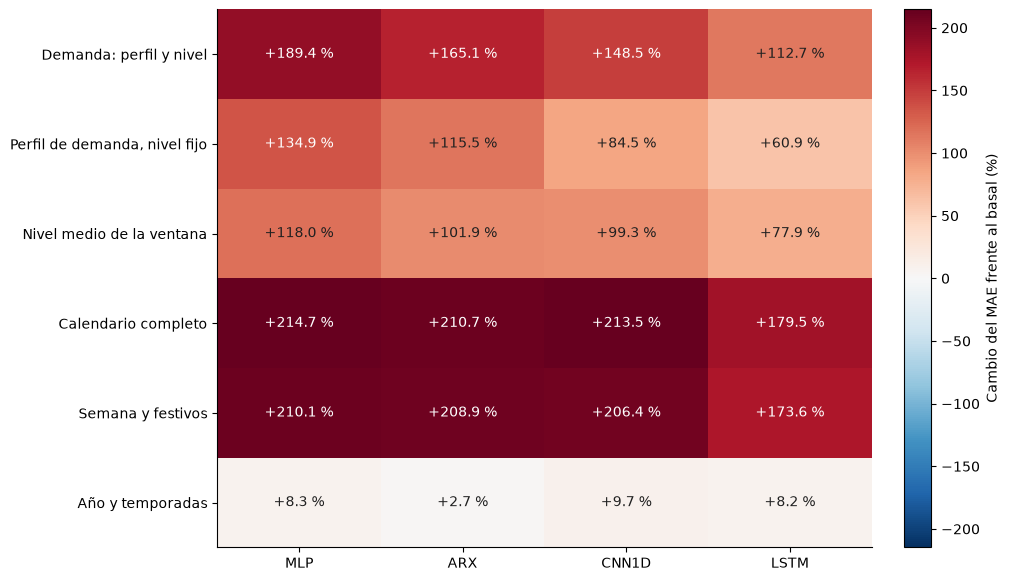

In [14]:
FI = ROOT/'results/jbook/importancia_variables'
reporte_fi = json.loads((FI/'ejecucion.json').read_text(encoding='utf-8'))
protocolo_fi = json.loads((FI/'protocolo.json').read_text(encoding='utf-8'))
fi = pd.read_csv(FI/'permutaciones.csv')
assert reporte_fi['completo'] and not reporte_fi['entrenamiento']
assert len(fi) == 2600 and not fi.duplicated(['modelo','semilla','grupo','repeticion']).any()
assert set(fi.modelo) == set(modelos)
assert set(fi.semilla) == set(range(1000,1005)) and set(fi.repeticion) == set(range(10))
# Primero se promedian las cinco inicializaciones dentro de cada permutación.
por_perm = fi.groupby(['modelo','grupo','repeticion'],sort=False)[['MAE_base','delta_MAE','delta_MASE']].mean().reset_index()
por_perm['delta_rel_pct'] = 100 * por_perm.delta_MAE / por_perm.MAE_base
resumen_fi = por_perm.groupby(['modelo','grupo'],sort=False).agg(
    cambio_MAE_pct=('delta_rel_pct','mean'),
    p10_perm_pct=('delta_rel_pct',lambda x:x.quantile(.1)),
    p90_perm_pct=('delta_rel_pct',lambda x:x.quantile(.9)),
    delta_MAE_kWh=('delta_MAE','mean'), delta_MASE=('delta_MASE','mean')).reset_index()
resumen_fi.to_csv(FI/'resumen.csv',index=False)
grupos_principales = ['demanda_completa','perfil_demanda','nivel_ventana',
                      'calendario_completo','semanal_festivos','anual_temporadas']
nombres_grupos = ['Demanda: perfil y nivel','Perfil de demanda, nivel fijo',
                 'Nivel medio de la ventana','Calendario completo',
                 'Semana y festivos','Año y temporadas']
matriz_fi = resumen_fi.pivot(index='grupo',columns='modelo',values='cambio_MAE_pct').reindex(
    index=grupos_principales,columns=modelos)
from matplotlib.colors import TwoSlopeNorm
lim_fi = float(np.max(np.abs(matriz_fi.to_numpy())))
fig, ax = plt.subplots(figsize=(10,5.7),layout='constrained')
im = ax.imshow(matriz_fi.to_numpy(),cmap='RdBu_r',
               norm=TwoSlopeNorm(vmin=-lim_fi,vcenter=0,vmax=lim_fi),aspect='auto')
ax.set(xticks=range(4),xticklabels=[etiquetas[m] for m in modelos],
       yticks=range(6),yticklabels=nombres_grupos)
ax.grid(False)
for i in range(6):
    for j in range(4):
        valor=matriz_fi.iloc[i,j]
        ax.text(j,i,f'{valor:+.1f} %',ha='center',va='center',
                color='white' if abs(valor)>.55*lim_fi else '#202020',fontsize=10)
fig.colorbar(im,ax=ax,label='Cambio del MAE frente al basal (%)')
fig.savefig(FI/'importancia_grupos.png',dpi=170)
display(fig)
plt.close(fig)
mlp_perfil=float(matriz_fi.loc['perfil_demanda','mlp'])
mlp_semana=float(matriz_fi.loc['semanal_festivos','mlp'])
mlp_anual=float(matriz_fi.loc['anual_temporadas','mlp'])
grupo_lider={etiquetas[m]:nombres_grupos[int(np.argmax(matriz_fi[m].to_numpy()))] for m in modelos}


En MLP, perturbar el perfil de demanda con nivel fijo aumenta el MAE un 134.9 %, mientras alterar semana y festivos lo incrementa un 210.1 %. Año y temporadas produce un cambio menor, del 8.3 %. El calendario laboral y la trayectoria reciente aportan información complementaria para reproducir el perfil diario. La importancia del nivel corresponde al procedimiento de normalización y restitución, además de las entradas explícitas de la red. La magnitud no es un porcentaje de varianza explicada ni una contribución aditiva. La correlación entre grupos y las combinaciones artificiales creadas al permutarlos limitan atribuciones individuales.

### Distribución de la sensibilidad a lo largo de la historia

Se perturban por separado los siete bloques consecutivos de 24 horas de demanda normalizada, manteniendo fijos el nivel y el calendario. El bloque 1 es el más reciente y el bloque 7 el más antiguo dentro de las 168 horas disponibles. Los puntos muestran la media; los segmentos, p10–p90 entre los diez desplazamientos después de promediar las cinco inicializaciones. Son dispersión de perturbaciones, no intervalos de confianza temporal.

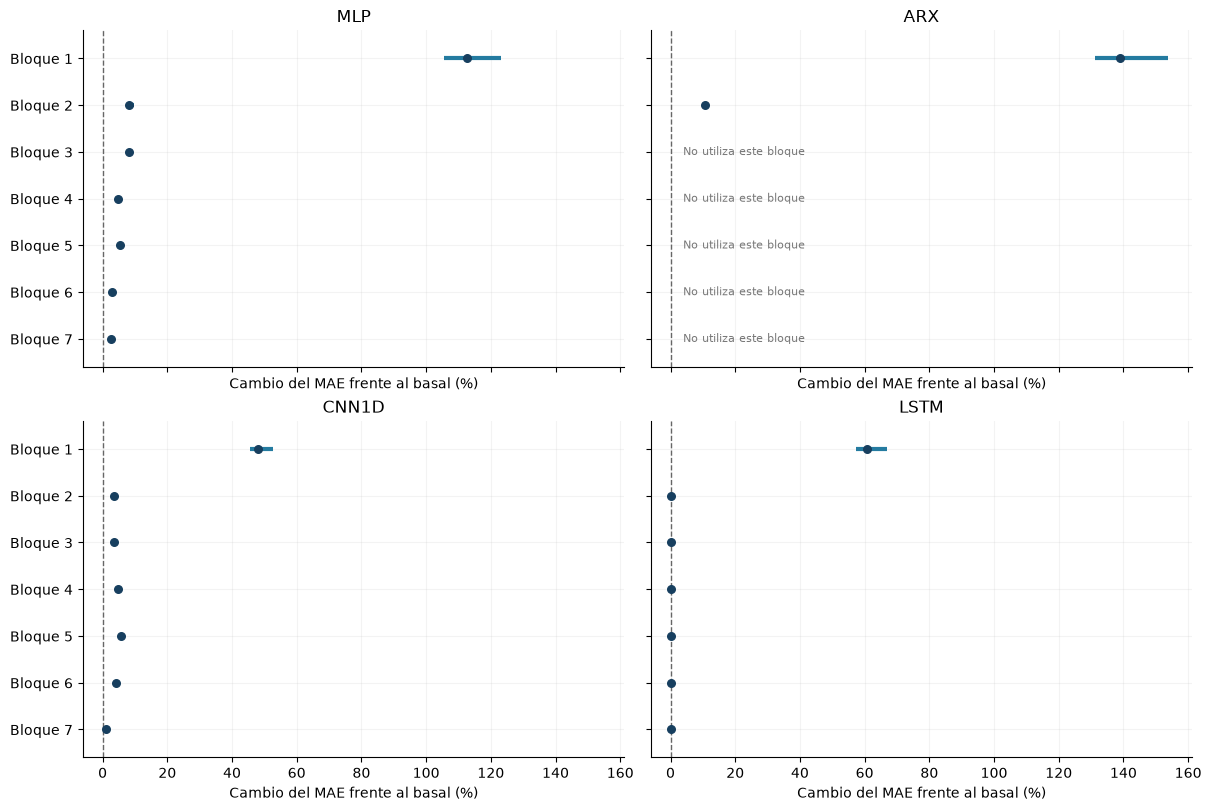

In [15]:
grupos_dias=[f'dia_{i}' for i in range(1,8)]
fig, axes=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True,layout='constrained')
q_dias=resumen_fi.loc[resumen_fi.grupo.isin(grupos_dias)]
xmin=min(0.,float(q_dias.p10_perm_pct.min()))
xmax=max(0.,float(q_dias.p90_perm_pct.max()))
for ax,m in zip(axes.ravel(),modelos):
    q=resumen_fi.loc[resumen_fi.modelo.eq(m)].set_index('grupo').loc[grupos_dias]
    for i,g in enumerate(grupos_dias):
        if m=='arx_lineal' and i>=2:
            ax.text(.06,i,'No utiliza este bloque',transform=ax.get_yaxis_transform(),
                    va='center',color='#777777',fontsize=8)
        else:
            ax.hlines(i,q.loc[g,'p10_perm_pct'],q.loc[g,'p90_perm_pct'],color='#247ba0',lw=3)
            ax.scatter(q.loc[g,'cambio_MAE_pct'],i,color='#173f5f',s=30,zorder=3)
    ax.axvline(0,color='#666666',ls='--',lw=1)
    ax.set(title=etiquetas[m],xlabel='Cambio del MAE frente al basal (%)',
           yticks=range(7),yticklabels=[f'Bloque {i}' for i in range(1,8)],
           xlim=(xmin-.04*(xmax-xmin),xmax*1.05),ylim=(6.6,-.6))
fig.savefig(FI/'importancia_rezagos.png',dpi=170)
display(fig)
plt.close(fig)
mlp_dias=resumen_fi.loc[resumen_fi.modelo.eq('mlp') & resumen_fi.grupo.isin(grupos_dias)].set_index('grupo')
mlp_bloque_lider=int(mlp_dias.cambio_MAE_pct.idxmax().split('_')[1])
mlp_ultimo_dia=float(mlp_dias.loc['dia_1','cambio_MAE_pct'])
lstm_antiguo=float(resumen_fi.loc[resumen_fi.modelo.eq('lstm') & resumen_fi.grupo.isin(grupos_dias[1:]),'cambio_MAE_pct'].abs().max())
lstm_antiguo_texto='inferior al 0,001 %' if lstm_antiguo<.001 else f'del {lstm_antiguo:.4f} %'
destino_fi=ROOT/'book/_static/resultados/importancia_variables'
destino_fi.mkdir(parents=True,exist_ok=True)
resumen_fi.to_csv(destino_fi/'resumen.csv',index=False)
fi.to_csv(destino_fi/'permutaciones.csv',index=False)
pd.read_csv(FI/'reproduccion_baseline.csv').to_csv(destino_fi/'reproduccion_baseline.csv',index=False)
for nombre in ['protocolo.json','ejecucion.json']:
    (destino_fi/nombre).write_text((FI/nombre).read_text(encoding='utf-8'),encoding='utf-8')


El bloque 1 es el de mayor sensibilidad en MLP: perturbar las últimas 24 horas aumenta su MAE un 112.6 %. La sensibilidad a los bloques anteriores es menor. ARX utiliza únicamente 48 rezagos; los bloques 3–7 quedan identificados como ausentes de su entrada. En LSTM, el cambio absoluto máximo de los bloques 2–7 es del 0.0083 %, compatible con una sensibilidad muy pequeña a esa parte del historial en este diagnóstico. Esa observación no demuestra que todas las redes recurrentes ignoren la historia larga.

### Alcance de la atribución

Las tres codificaciones de hora son idénticas entre orígenes diarios iniciados a medianoche. Permutar orígenes deja ese bloque inalterado; su importancia no es identificable mediante este procedimiento y no se reporta como cero. La salida directa de 24 posiciones también representa la posición horaria.

El desplazamiento preserva las trayectorias de cada bloque, pero rompe dependencias entre demanda, calendario y objetivo. Por ello mide sensibilidad ante perturbaciones fuera de la combinación observada y no estima el efecto de retirar una variable y reentrenar. Los grupos correlacionados pueden sustituirse parcialmente; una importancia pequeña no acredita irrelevancia intrínseca. La prueba conserva su alcance retrospectivo y estos resultados no modifican arquitecturas, selección de entradas ni métricas del benchmark.

[Resumen de importancias](_static/resultados/importancia_variables/resumen.csv) · [Resultados por semilla y desplazamiento](_static/resultados/importancia_variables/permutaciones.csv) · [Reproducción del baseline](_static/resultados/importancia_variables/reproduccion_baseline.csv) · [Protocolo](_static/resultados/importancia_variables/protocolo.json) · [Registro de cálculo](_static/resultados/importancia_variables/ejecucion.json).

### Pipeline reproducible de inferencia y perturbación

El siguiente código utiliza los checkpoints y escaladores conservados, verifica sus huellas, reproduce el baseline y calcula las perturbaciones. La construcción documental lee sus CSV; el cálculo se ejecuta explícitamente con `python scripts/importancia_variables.py` en un entorno con PyTorch CPU. No contiene pasos de optimización.

```python
"""Importancia agrupada mediante inferencia de checkpoints congelados."""
from pathlib import Path
from types import SimpleNamespace
import argparse
import hashlib
import json
import platform
import sys
import time
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
MODELOS = ['mlp', 'arx_lineal', 'cnn1d', 'lstm']
REPETICIONES = 10
SEMILLA_PERMUTACION = 11037
GRUPOS_CAL = {
    'semanal_festivos': ['cal_dow', 'cal_es_festivo', 'cal_es_domingo',
        'cal_es_sabado', 'cal_es_no_laboral', 'cal_tipo_dia',
        'cal_dias_al_siguiente_festivo', 'cal_dias_desde_festivo_previo',
        'cal_es_vispera_festivo', 'cal_es_dia_post_festivo',
        'cal_es_fin_semana_largo', 'cal_dow_sin', 'cal_dow_cos'],
    'anual_temporadas': ['cal_mes', 'cal_dia_anio', 'cal_es_semana_santa',
        'cal_es_temporada_navidena', 'cal_es_fin_de_anio', 'cal_doy_sin', 'cal_doy_cos'],
    'hora': ['cal_hora', 'cal_hora_sin', 'cal_hora_cos'],
}
GRUPOS = ['demanda_completa', 'perfil_demanda', 'nivel_ventana',
          'calendario_completo', 'semanal_festivos', 'anual_temporadas'] + [f'dia_{i}' for i in range(1, 8)]


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def indices_donantes(fechas, repeticion):
    """Traslada circularmente orígenes completos dentro de cada año."""
    rng = np.random.default_rng(SEMILLA_PERMUTACION + repeticion)
    perm = np.arange(len(fechas))
    for anio in sorted(set(fechas.year)):
        ix = np.flatnonzero(fechas.year == anio)
        if len(ix) < 57:
            raise ValueError('Se requieren al menos 57 orígenes diarios por año')
        desplazamiento = int(rng.integers(28, len(ix) - 27))
        perm[ix] = np.roll(ix, desplazamiento)
    assert np.array_equal(np.sort(perm), np.arange(len(fechas)))
    assert np.array_equal(fechas.year[perm], fechas.year)
    assert np.all(perm != np.arange(len(fechas)))
    return perm


def perturbar(xp, cf, nivel, donantes, grupo, columnas_cal):
    """Copia solo el grupo perturbado; las etiquetas nunca entran aquí."""
    if grupo not in GRUPOS:
        raise ValueError(f'Grupo no reconocido: {grupo}')
    x, c, n = xp, cf, nivel
    if grupo in ('demanda_completa', 'perfil_demanda'):
        x = xp.copy()
        x[:, :, 0] = xp[donantes, :, 0]
    if grupo in ('demanda_completa', 'nivel_ventana'):
        n = nivel[donantes]
    if grupo.startswith('dia_'):
        dia = int(grupo.split('_')[1])
        lo, hi = xp.shape[1] - 24 * dia, xp.shape[1] - 24 * (dia - 1)
        x = xp.copy()
        x[:, lo:hi, 0] = xp[donantes, lo:hi, 0]
    if grupo in ('calendario_completo', 'semanal_festivos', 'anual_temporadas'):
        cols = columnas_cal if grupo == 'calendario_completo' else GRUPOS_CAL[grupo]
        ix = [columnas_cal.index(k) for k in cols]
        x = xp.copy()
        c = cf.copy()
        # xp concatena demanda y calendario pasado; cf conserva calendario futuro.
        x[:, :, np.asarray(ix) + 1] = xp[donantes][:, :, np.asarray(ix) + 1]
        c[:, :, ix] = cf[donantes][:, :, ix]
    return x, c, n


def restaurar_entradas(panel, fechas, escalador):
    """Usa solo escaladores publicados; no ajusta estadísticas."""
    cols = escalador['columnas_cal']
    assert escalador['columnas_x'] == ['x_demanda_real_kwh']
    assert escalador['datos']['ventana'] == 168
    assert escalador['datos']['normalizacion'] == 'nivel'
    assert pd.Timestamp(escalador['fin_ajuste']) < pd.Timestamp('2022-01-01', tz='America/Bogota')
    pos = panel.index.get_indexer(fechas)
    assert (pos >= 168).all()
    pasada = pos[:, None] - np.arange(168, 0, -1)
    futura = pos[:, None] + np.arange(24)
    assert np.all(panel.index.asi8[pasada[:, -1]] < fechas.asi8)
    historia = panel['x_demanda_real_kwh'].to_numpy(dtype=np.float64)[pasada]
    nivel = historia.mean(axis=1)
    x = (historia / nivel[:, None]).astype('float32')
    if escalador['secuencial']:
        x = (x - 1.) / escalador['sigma_demanda']
    media = np.array([escalador['media'][k] for k in cols])
    std = np.array([escalador['std'][k] for k in cols])
    cal = panel[cols].to_numpy(dtype=np.float64)
    cp = ((cal[pasada] - media) / std).astype('float32')
    cf = ((cal[futura] - media) / std).astype('float32')
    y = panel['y_demanda_real_kwh'].to_numpy()[futura]
    xp = np.concatenate([x[:, :, None], cp], axis=2)
    assert xp.dtype == cf.dtype == np.float32
    assert np.isfinite(xp).all() and np.isfinite(cf).all() and (nivel > 0).all()
    indices_hora = [cols.index(k) for k in GRUPOS_CAL['hora']]
    assert all(np.array_equal(cp[:, :, j], np.broadcast_to(cp[0:1, :, j], cp[:, :, j].shape)) for j in indices_hora)
    assert all(np.array_equal(cf[:, :, j], np.broadcast_to(cf[0:1, :, j], cf[:, :, j].shape)) for j in indices_hora)
    return xp, cf, nivel, y, cols


def predecir(red, xp, cf, nivel, torch):
    salida = []
    for i in range(0, len(nivel), 256):
        yhat = red(torch.from_numpy(xp[i:i+256]), torch.from_numpy(cf[i:i+256]))
        salida.append(yhat.cpu().numpy())
    pred = np.concatenate(salida).astype(np.float64) * nivel[:, None]
    assert pred.shape == (len(nivel), 24) and np.isfinite(pred).all()
    return pred


def ejecutar(verificar=False):
    import torch
    torch.set_num_threads(1)
    torch.set_num_interop_threads(1)
    torch.use_deterministic_algorithms(True)
    torch.manual_seed(SEMILLA_PERMUTACION)
    sha = json.loads((ROOT/'results/jbook/modelos_actualizados.json').read_text())['commit']
    snapshot = ROOT/'results/repositorio'/sha
    sys.path.insert(0, str(snapshot/'src'))
    from demanda import modelos_base as M
    from demanda.reentrenamiento_v3 import Secuencial as CNN
    from demanda.variantes_v4 import Secuencial as LSTM
    registro = json.loads((snapshot/'results/consolidado/modelos.json').read_text(encoding='utf-8'))
    huellas = {r['archivo']:r['sha256'] for r in json.loads((snapshot/'IMPORTACION.json').read_text(encoding='utf-8'))['archivos']}
    out = ROOT/'results/jbook/importancia_variables'
    out.mkdir(parents=True, exist_ok=True)
    protocolo = dict(version=1, escenario='diagnostico_retrospectivo_prueba_2022_2025',
        modelos=MODELOS, semillas=list(range(1000,1005)), repeticiones=REPETICIONES,
        semilla_permutacion=SEMILLA_PERMUTACION, grupos=GRUPOS,
        grupos_calendario=GRUPOS_CAL, donantes='desplazamiento_circular_por_anio',
        desplazamiento_minimo_dias=28, denominador_mase=215617.90361589016,
        dispositivo='cpu', hilos=1, batch=256, entrenamiento=False,
        reajuste_escaladores=False, seleccion_con_resultados=False,
        hora='invariante_entre_origenes_no_identificable_con_esta_permutacion')
    p = out/'protocolo.json'
    if p.exists():
        assert json.loads(p.read_text(encoding='utf-8'))['protocolo'] == protocolo
    else:
        p.write_text(json.dumps(dict(registrado=pd.Timestamp.now(tz='America/Bogota').isoformat(),
            protocolo=protocolo), ensure_ascii=False, indent=2), encoding='utf-8')
    primer = registro['mlp']['artefactos'][0]
    with np.load(snapshot/primer['predicciones'], allow_pickle=False) as z:
        fechas = pd.to_datetime(z['origen'], unit='ns', utc=True).tz_convert('America/Bogota')
    assert fechas.equals(pd.date_range('2022-01-01','2025-12-31',freq='D',tz='America/Bogota'))
    cols = json.loads((snapshot/primer['escaladores']).read_text(encoding='utf-8'))['columnas_cal']
    assert sorted(sum(GRUPOS_CAL.values(), [])) == sorted(cols)
    panel = pd.read_parquet(ROOT/'data/processed/panel_horario.parquet', columns=['x_demanda_real_kwh','y_demanda_real_kwh',*cols])
    donantes = [indices_donantes(fechas,r) for r in range(REPETICIONES)]
    np.savez_compressed(out/'donantes.npz', fechas_utc=fechas.asi8, indices=np.stack(donantes))
    benchmark_path = ROOT/'results/jbook/modelos_actuales/benchmark.csv'
    benchmark_hash = sha256(benchmark_path)
    filas, validaciones = [], []
    inicio = time.perf_counter()
    with torch.inference_mode():
        for nombre in MODELOS:
            for a in sorted(registro[nombre]['artefactos'], key=lambda x:x['semilla']):
                for campo in ('pesos','escaladores','predicciones'):
                    assert sha256(snapshot/a[campo]) == huellas[a[campo]]
                esc = json.loads((snapshot/a['escaladores']).read_text(encoding='utf-8'))
                xp, cf, nivel, y, cols = restaurar_entradas(panel, fechas, esc)
                shapes = SimpleNamespace(x=xp[:, :, :1], cal_p=xp[:, :, 1:], cal_f=cf)
                params = registro[nombre]['configuracion']['params']
                red = (LSTM(nombre, params, shapes) if nombre=='lstm' else
                       CNN(nombre, params, shapes) if nombre=='cnn1d' else
                       M.construir_red(nombre, params, shapes))
                ck = torch.load(snapshot/a['pesos'], map_location='cpu', weights_only=True)
                red.load_state_dict(ck['state_dict'], strict=True)
                red.eval()
                esperado = np.load(snapshot/a['predicciones'], allow_pickle=False)
                assert np.array_equal(esperado['y'], y)
                assert np.array_equal(esperado['origen'], fechas.asi8)
                base = predecir(red, xp, cf, nivel, torch)
                error = np.abs(base-y)
                mae = error.mean()
                diferencia = float(np.max(np.abs(base-esperado['yhat'])))
                diferencia_mae = float(abs(mae-np.abs(esperado['yhat']-y).mean()))
                assert diferencia < 100 and diferencia_mae < 5, (nombre, diferencia, diferencia_mae)
                validaciones.append(dict(modelo=nombre, semilla=a['semilla'],
                    max_diferencia_pred_kWh=diferencia, diferencia_MAE_kWh=diferencia_mae,
                    MAE_cpu_kWh=float(mae), checkpoint_sha256=huellas[a['pesos']]))
                if not verificar:
                    for grupo in GRUPOS:
                        if nombre=='arx_lineal' and grupo.startswith('dia_') and int(grupo[4:])>2:
                            for r in range(REPETICIONES):
                                filas.append(dict(modelo=nombre,semilla=a['semilla'],grupo=grupo,
                                    repeticion=r,usa_grupo=False,MAE_base=mae,MAE_perturbado=mae,
                                    delta_MAE=0.,delta_MASE=0.,delta_rel_pct=0.))
                            continue
                        for r, perm in enumerate(donantes):
                            x, c, n = perturbar(xp, cf, nivel, perm, grupo, cols)
                            pred = predecir(red, x, c, n, torch)
                            nuevo = float(np.abs(pred-y).mean())
                            filas.append(dict(modelo=nombre,semilla=a['semilla'],grupo=grupo,
                                repeticion=r,usa_grupo=True,MAE_base=mae,MAE_perturbado=nuevo,
                                delta_MAE=nuevo-mae,delta_MASE=(nuevo-mae)/esc['escala_mase'],
                                delta_rel_pct=100*(nuevo/mae-1)))
                pd.DataFrame(validaciones).to_csv(out/'reproduccion_baseline.csv', index=False)
                if filas:
                    pd.DataFrame(filas).to_csv(out/'permutaciones.csv', index=False)
                print(f"{nombre} semilla {a['semilla']}: {'verificado' if verificar else 'completo'}; {time.perf_counter()-inicio:.1f} s", flush=True)
    assert sha256(benchmark_path) == benchmark_hash
    reporte = dict(completo=True,solo_verificacion=verificar,horas=35064,origenes=1461,
        modelos=4,checkpoints=20,repeticiones=REPETICIONES,grupos=len(GRUPOS),
        filas=len(filas),entrenamiento=False,publicado=False,benchmark_intacto=True,
        max_diferencia_pred_kWh=max(r['max_diferencia_pred_kWh'] for r in validaciones),
        max_diferencia_MAE_kWh=max(r['diferencia_MAE_kWh'] for r in validaciones),
        duracion_segundos=time.perf_counter()-inicio,torch=torch.__version__,
        numpy=np.__version__,pandas=pd.__version__,sistema=platform.platform(),
        codigo_sha256=sha256(Path(__file__)))
    (out/('validacion.json' if verificar else 'ejecucion.json')).write_text(json.dumps(reporte, ensure_ascii=False, indent=2), encoding='utf-8')
    print(json.dumps(reporte,ensure_ascii=False),flush=True)


if __name__=='__main__':
    parser=argparse.ArgumentParser()
    parser.add_argument('--verificar', action='store_true')
    ejecutar(parser.parse_args().verificar)

```

## Lectura conjunta

La MLP constituye la referencia empírica del benchmark por su MASE agregado. La evaluación temporal permite comprobar si esa posición se mantiene entre horas, años y tipos de día. La cercanía global entre ARX y CNN1D debe contrastarse con sus perfiles y costos, sin reducir la elección a una única diferencia puntual. Las cinco inicializaciones y los intervalos temporales describen fuentes de variación distintas.

Los archivos derivados se conservan en results/jbook/modelos_actuales. El análisis reproduce métricas desde predicciones guardadas y no modifica pesos, escaladores ni configuraciones.

## Margen relativo e interpretación de los contrastes

El preregistro confirma δ=3 % como diferencia relativa de interés. Para toda pareja se define θ_AB=(μ_A−μ_B)/μ_MLP: el piloto estima su dispersión relativa y TOST contrasta el mismo intervalo [−0,03;0,03]. El umbral operativo para un modelo avanzado es μ_nuevo<0,97·μ_MLP.

Los IC90 % de Fieller incorporan covarianza entre numerador y referencia, bajo normalidad bivariada, conforme a la [formulación para muestras pareadas de NIST](https://www.itl.nist.gov/div898/software/dataplot/refman1/auxillar/ratimean.htm). La decisión tras Holm no se deduce sólo de un IC90 % individual. Con cinco semillas estos supuestos tienen verificación limitada.

Las t pareadas con Holm y los contrastes temporales encuentran diferencias entre MLP, CNN1D y LSTM en los datos evaluados. Wilcoxon exacto no rechaza con cinco pares. ARX y CNN1D no presentan una diferencia temporal significativa; tampoco se acredita equivalencia mediante TOST. Detectar diferencias mayores no acredita potencia del 80 % para una mejora del 3 %, y los resultados mantienen alcance exploratorio por la selección adaptativa y la exposición al conjunto de prueba.

## Fundamento metodológico

Las implementaciones consultan la documentación de [Shapiro–Wilk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html), [Wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html), [rango studentizado](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.studentized_range.html) y [TOST pareado](https://www.statsmodels.org/stable/generated/statsmodels.stats.weightstats.ttost_paired.html). [Demšar (2006)](https://jmlr.org/papers/v7/demsar06a.html) desarrolla comparaciones por rangos entre conjuntos de datos; aquí se explicita que los bloques son inicializaciones de un mismo conjunto, con inferencia condicional y no generalización entre sistemas eléctricos. Los p conservan notación científica; valores numéricamente subdesbordados se muestran como <1e-300.